# Scout: resumo dos resultados

Este notebook **não treina modelos e não baixa dados**. Ele só lê os resultados que já estão salvos no repositório e mostra tudo em gráficos.

| Estudo | De onde o número foi lido |
| --- | --- |
| SIRP-600 | `sirp-600/notebooks/analise_risco_lesao_sirp600.ipynb`, saídas das células 5 e 11 |
| Multimodal Injury | `multimodal_injury/multimodal_sports_injury_pipeline.ipynb`, células 7 e 15; correlações do `README.md` |
| SoccerMon | `soccermon/soccermon_pipeline.ipynb`, células 17 e 21 |
| Shalaj | `shalaj/results/summary.json` |
| University Football | `university_football/results/summary.json` |
| SoccerNet-GSR | `soccernet_gsr/results/summary.json` |

**Como ler as notas:** ROC-AUC vai de 0,5 (chute) a 1 (acerto perfeito). PR-AUC mostra quanto o modelo acerta quando dá um alerta, e deve ser comparada com a prevalência (a porcentagem de casos de lesão na base).

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AQUI = Path.cwd()
RAIZ = AQUI.parent if AQUI.name == "resultados_simplificados" else AQUI
FIGURAS = RAIZ / "resultados_simplificados" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold"})
COR_DADOS = {"Real": "#2c7fb8", "Suspeito": "#f0a030", "Inventado": "#c0392b"}
PLURAL = {"Real": "reais", "Suspeito": "suspeitos", "Inventado": "inventados"}
RISCO, PROTECAO = "#c0392b", "#2e8b57"

def saida_da_celula(notebook, numero):
    """Texto salvo na saída de uma célula do notebook original (contando a partir de 1)."""
    nb = json.loads((RAIZ / notebook).read_text(encoding="utf-8"))
    cel = nb["cells"][numero - 1]
    return "\n".join("".join(o.get("text", [])) + "".join(o.get("data", {}).get("text/plain", []))
                   for o in cel.get("outputs", []))

def pegar(texto, rotulo):
    """Primeiro número de 4 casas na linha que contém o rótulo."""
    return float(re.search(rf"{re.escape(rotulo)}[^\n]*?(\d\.\d{{4}})", texto).group(1))

def br(v, casas=2):
    return f"{v:.{casas}f}".replace(".", ",")

def salvar(nome):
    plt.savefig(FIGURAS / nome, dpi=150, bbox_inches="tight")
    plt.show()

print("Pasta do repositório:", RAIZ)

Pasta do repositório: C:\Users\vagne\OneDrive\Documentos\scout_cruzamento


## 1. As notas de cada estudo

Os números abaixo são lidos das saídas salvas pelos estudos originais.

In [2]:
SIRP_NB = "sirp-600/notebooks/analise_risco_lesao_sirp600.ipynb"
MULTI_NB = "multimodal_injury/multimodal_sports_injury_pipeline.ipynb"
MON_NB = "soccermon/soccermon_pipeline.ipynb"

sirp_txt = saida_da_celula(SIRP_NB, 11)
multi_txt = saida_da_celula(MULTI_NB, 15)
mon_txt = saida_da_celula(MON_NB, 17)
shalaj = json.loads((RAIZ / "shalaj/results/summary.json").read_text(encoding="utf-8"))
uf = json.loads((RAIZ / "university_football/results/summary.json").read_text(encoding="utf-8"))
gsr = json.loads((RAIZ / "soccernet_gsr/results/summary.json").read_text(encoding="utf-8"))

sirp_prev = float(re.search(r"Lesionado \(1\)\s+([\d.]+)%", saida_da_celula(SIRP_NB, 5)).group(1)) / 100
multi_prev = float(re.search(r"Prevalência: ([\d.]+)%", saida_da_celula(MULTI_NB, 7)).group(1)) / 100
mon_pos = int(re.search(r"\n\s*Lesão \(1\)\s+\S+\s+\S+\s+\S+\s+(\d+)", mon_txt).group(1))
mon_neg = int(re.search(r"Sem Lesão \(0\)\s+\S+\s+\S+\s+\S+\s+(\d+)", mon_txt).group(1))
uf_m = uf["metrics_label_classification_oof"]["logistica"]
sh_m = shalaj["metrics_oof"]["rf_sigmoid"]

estudos = pd.DataFrame([
    {"Estudo": "University Football", "Dados": "Suspeito", "Amostra": "800 atletas",
     "ROC-AUC": uf_m["roc_auc"], "PR-AUC": uf_m["average_precision"], "Prevalência": uf["audit"]["prevalence"]},
    {"Estudo": "SIRP-600", "Dados": "Inventado", "Amostra": "600 atletas",
     "ROC-AUC": pegar(sirp_txt, "ROC-AUC"), "PR-AUC": pegar(sirp_txt, "PR-AUC"), "Prevalência": sirp_prev},
    {"Estudo": "Multimodal Injury", "Dados": "Suspeito", "Amostra": "15.420 treinos",
     "ROC-AUC": pegar(multi_txt, "ROC-AUC"), "PR-AUC": pegar(multi_txt, "PR-AUC"), "Prevalência": multi_prev},
    {"Estudo": "SoccerMon", "Dados": "Real", "Amostra": "36.550 atleta-dias",
     "ROC-AUC": pegar(mon_txt, "ROC-AUC"), "PR-AUC": pegar(mon_txt, "PR-AUC"), "Prevalência": mon_pos / (mon_pos + mon_neg)},
    {"Estudo": "Shalaj", "Dados": "Real", "Amostra": "143 atletas",
     "ROC-AUC": sh_m["roc_auc"], "PR-AUC": sh_m["average_precision"], "Prevalência": shalaj["prevalence"]},
])
estudos.style.format({"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}", "Prevalência": "{:.1%}"}).hide(axis="index")

Estudo,Dados,Amostra,ROC-AUC,PR-AUC,Prevalência
University Football,Suspeito,800 atletas,0.990,0.990,50.0%
SIRP-600,Inventado,600 atletas,0.902,0.824,31.5%
Multimodal Injury,Suspeito,15.420 treinos,0.881,0.549,15.0%
SoccerMon,Real,36.550 atleta-dias,0.841,0.035,0.3%
Shalaj,Real,143 atletas,0.824,0.627,28.0%


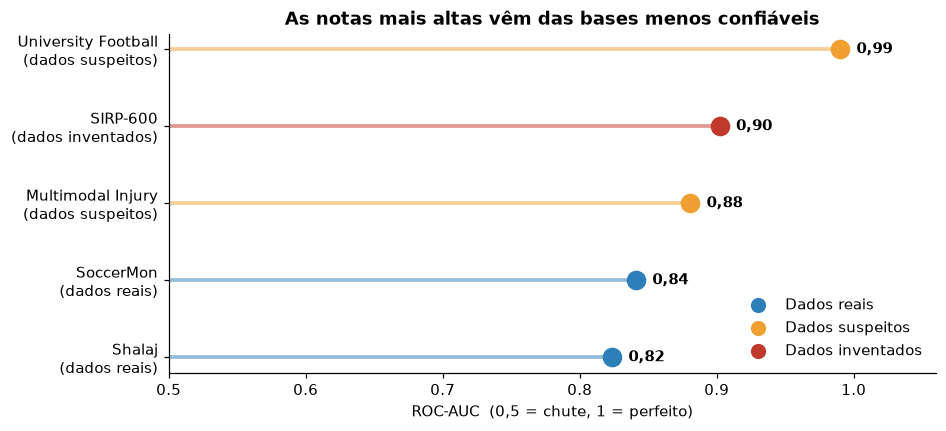

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(estudos))[::-1]
for yi, (_, r) in zip(y, estudos.iterrows()):
    cor = COR_DADOS[r["Dados"]]
    ax.plot([0.5, r["ROC-AUC"]], [yi, yi], color=cor, lw=2.5, alpha=0.5)
    ax.scatter(r["ROC-AUC"], yi, s=140, color=cor, zorder=3)
    ax.text(r["ROC-AUC"] + 0.012, yi, br(r["ROC-AUC"]), va="center", fontweight="bold")
ax.set_yticks(y, [f"{e}\n(dados {PLURAL[d]})" for e, d in zip(estudos["Estudo"], estudos["Dados"])])
ax.set_xlim(0.5, 1.06)
ax.set_xlabel("ROC-AUC  (0,5 = chute, 1 = perfeito)")
ax.set_title("As notas mais altas vêm das bases menos confiáveis")
for nome, cor in COR_DADOS.items():
    ax.scatter([], [], color=cor, s=80, label=f"Dados {PLURAL[nome]}")
ax.legend(loc="lower right", frameon=False)
salvar("01_nota_por_estudo.png")

## 2. Quando o modelo dá um alerta, quantas vezes ele acerta?

A ROC-AUC sozinha engana quando a lesão é rara. A PR-AUC mostra a precisão dos alertas. O certo é comparar com a prevalência, que é o que um chute acertaria.

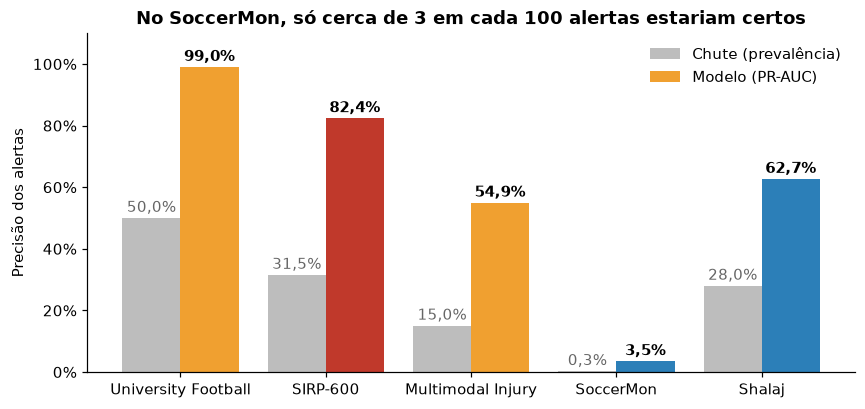

SoccerMon no teste: 28 dias com lesão e 10.672 dias sem lesão (0.26%).


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(estudos))
ax.bar(x - 0.2, estudos["Prevalência"], width=0.4, color="#bdbdbd", label="Chute (prevalência)")
ax.bar(x + 0.2, estudos["PR-AUC"], width=0.4, color=[COR_DADOS[d] for d in estudos["Dados"]], label="Modelo (PR-AUC)")
for xi, (p, m) in enumerate(zip(estudos["Prevalência"], estudos["PR-AUC"])):
    ax.text(xi + 0.2, m + 0.02, f"{m:.1%}".replace(".", ","), ha="center", fontweight="bold")
    ax.text(xi - 0.2, p + 0.02, f"{p:.1%}".replace(".", ","), ha="center", color="#666666")
ax.set_xticks(x, estudos["Estudo"])
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("Precisão dos alertas")
ax.set_title("No SoccerMon, só cerca de 3 em cada 100 alertas estariam certos")
ax.legend(frameon=False, loc="upper right")
salvar("02_precisao_dos_alertas.png")
print(f"SoccerMon no teste: {mon_pos} dias com lesão e {mon_neg:,} dias sem lesão ({mon_pos / (mon_pos + mon_neg):.2%}).".replace(",", "."))

## 3. O que anda junto com lesão: o que se repete e o que não se repete

Cada quadrado é uma correlação com lesão. **Vermelho** = quanto mais alto, mais lesão. **Verde** = quanto mais alto, menos lesão. Cinza = a base não tem essa informação.

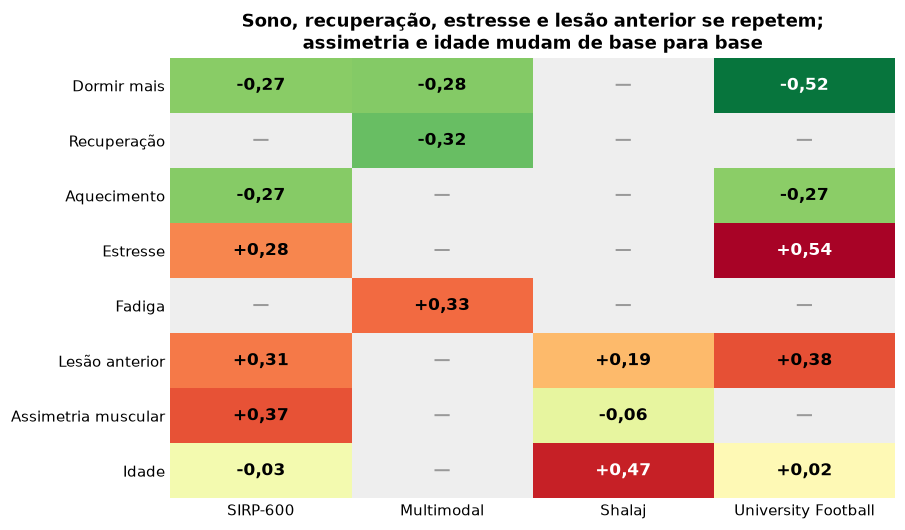

,SIRP-600,Multimodal,Shalaj,University Football
Dormir mais,-0.27,-0.28,NaN,-0.52
Recuperação,NaN,-0.32,NaN,NaN
Aquecimento,-0.27,NaN,NaN,-0.27
Estresse,0.28,NaN,NaN,0.54
Fadiga,NaN,0.33,NaN,NaN
Lesão anterior,0.31,NaN,0.19,0.38
Assimetria muscular,0.37,NaN,-0.06,NaN
Idade,-0.03,NaN,0.47,0.02


In [5]:
# SIRP-600: tabela de correlação salva na saída da célula 5
sirp_corr = {nome.strip(): float(r) for nome, r, _ in
             re.findall(r"^(\S.*?)\s{2,}(-?\d\.\d{3})\s+(-?\d\.\d{3})\s*$", saida_da_celula(SIRP_NB, 5), re.M)}
# Multimodal: valores de Spearman registrados no multimodal_injury/README.md
multi_corr = {"Índice de fadiga": 0.334, "Escore de recuperação (HRV)": -0.323, "Qualidade do sono": -0.278,
              "Carga total de treino": 0.228, "ACWR (carga aguda/crônica)": 0.142}
shalaj_corr = {a["feature"]: a["spearman"] for a in shalaj["associations"]}
uf_corr = uf["spearman"]

mapa = pd.DataFrame({
    "SIRP-600": {"Dormir mais": sirp_corr["Horas de Sono (h/dia)"], "Estresse": sirp_corr["Nível de Estresse (1-10)"],
                 "Lesão anterior": sirp_corr["Histórico de Lesões (qtd)"], "Aquecimento": sirp_corr["Tempo de Aquecimento (min)"],
                 "Assimetria muscular": sirp_corr["Assimetria Muscular (%)"], "Idade": sirp_corr["Idade (anos)"]},
    "Multimodal": {"Dormir mais": multi_corr["Qualidade do sono"], "Fadiga": multi_corr["Índice de fadiga"],
                   "Recuperação": multi_corr["Escore de recuperação (HRV)"]},
    "Shalaj": {"Lesão anterior": shalaj_corr["previous_hamstring_injury"], "Assimetria muscular": shalaj_corr["hamstring_asymmetry_60_pct"],
               "Idade": shalaj_corr["age"]},
    "University Football": {"Dormir mais": uf_corr["Sleep_Hours_Per_Night"], "Estresse": uf_corr["Stress_Level_Score"],
                            "Lesão anterior": uf_corr["Previous_Injury_Count"], "Aquecimento": uf_corr["Warmup_Routine_Adherence"],
                            "Idade": uf_corr["Age"]},
}).reindex(["Dormir mais", "Recuperação", "Aquecimento", "Estresse", "Fadiga", "Lesão anterior", "Assimetria muscular", "Idade"])

fig, ax = plt.subplots(figsize=(8.5, 5.2))
cmap = plt.get_cmap("RdYlGn_r").copy(); cmap.set_bad("#eeeeee")
ax.imshow(np.ma.masked_invalid(mapa.values.astype(float)), cmap=cmap, vmin=-0.55, vmax=0.55, aspect="auto")
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.iat[i, j]
        ax.text(j, i, "—" if pd.isna(v) else f"{v:+.2f}".replace(".", ","), ha="center", va="center",
                fontsize=11, fontweight="bold",
                color="#999999" if pd.isna(v) else ("white" if abs(v) >= 0.45 else "black"))
ax.set_xticks(range(mapa.shape[1]), mapa.columns)
ax.set_yticks(range(mapa.shape[0]), mapa.index)
ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Sono, recuperação, estresse e lesão anterior se repetem;\nassimetria e idade mudam de base para base")
salvar("03_o_que_se_repete.png")
mapa.round(2)

## 4. As correlações mais fortes de cada base

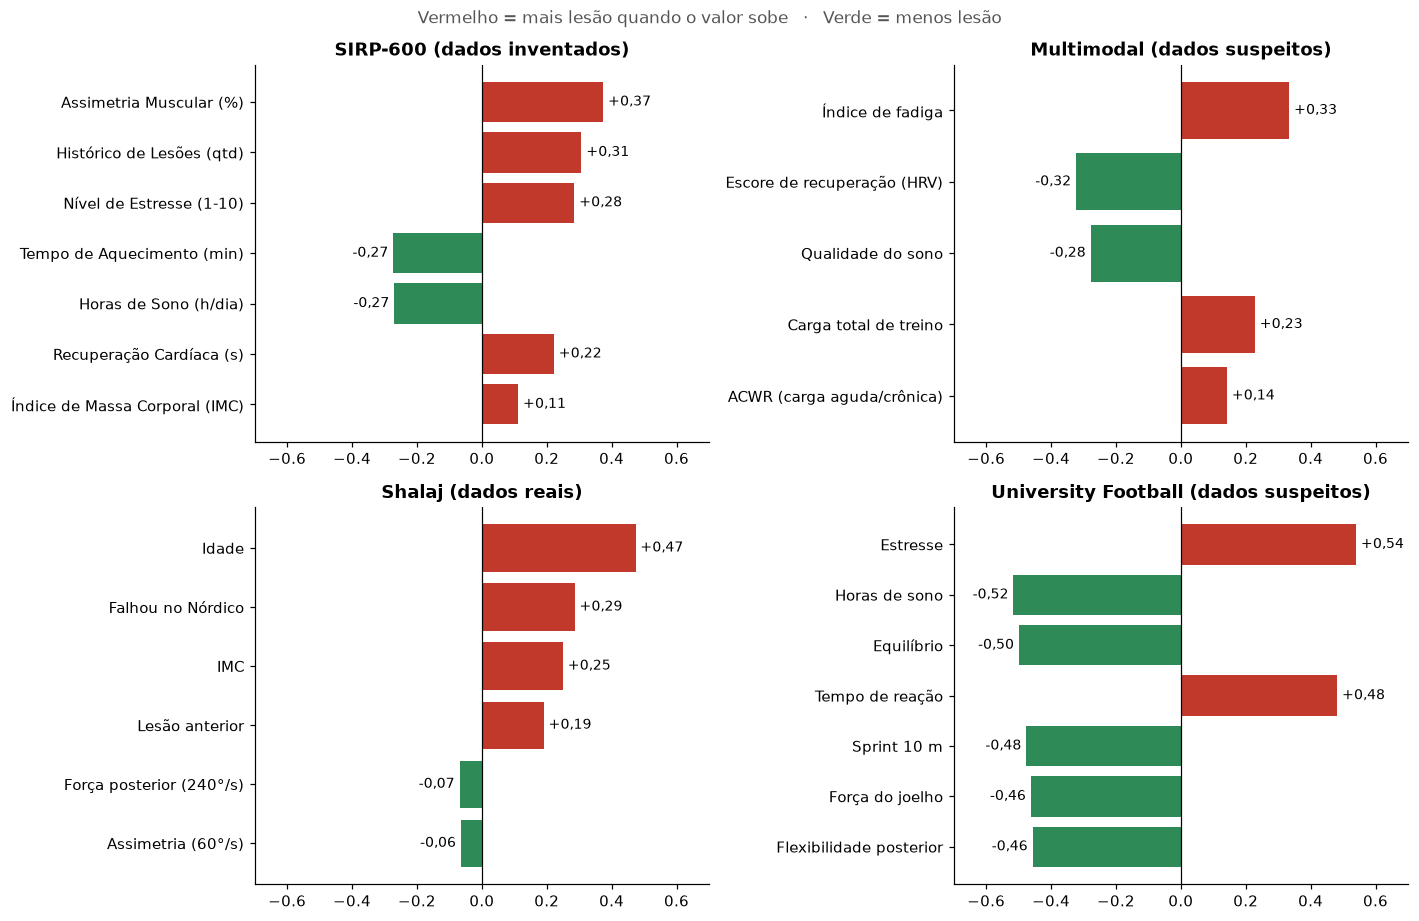

In [6]:
nomes_uf = {"Stress_Level_Score": "Estresse", "Sleep_Hours_Per_Night": "Horas de sono", "Balance_Test_Score": "Equilíbrio",
            "Reaction_Time_ms": "Tempo de reação", "Sprint_Speed_10m_s": "Sprint 10 m", "Knee_Strength_Score": "Força do joelho",
            "Hamstring_Flexibility": "Flexibilidade posterior", "Nutrition_Quality_Score": "Alimentação",
            "Agility_Score": "Agilidade", "Previous_Injury_Count": "Lesões anteriores", "Warmup_Routine_Adherence": "Faz aquecimento"}
nomes_sh = {"age": "Idade", "nordic_failed": "Falhou no Nórdico", "bmi": "IMC", "previous_hamstring_injury": "Lesão anterior",
            "hamstring_relative_240_mean": "Força posterior (240°/s)", "hamstring_asymmetry_60_pct": "Assimetria (60°/s)"}
paineis = {
    "SIRP-600 (dados inventados)": pd.Series(sirp_corr),
    "Multimodal (dados suspeitos)": pd.Series(multi_corr),
    "Shalaj (dados reais)": pd.Series({nomes_sh[k]: v for k, v in shalaj_corr.items()}),
    "University Football (dados suspeitos)": pd.Series({nomes_uf.get(k, k): v for k, v in uf_corr.items()}),
}
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, (titulo, s) in zip(axes.flat, paineis.items()):
    s = s.reindex(s.abs().sort_values().index).tail(7)
    ax.barh(s.index, s.values, color=[RISCO if v > 0 else PROTECAO for v in s.values])
    ax.axvline(0, color="black", lw=0.8)
    for i, v in enumerate(s.values):
        ax.text(v + (0.015 if v >= 0 else -0.015), i, f"{v:+.2f}".replace(".", ","), va="center",
                ha="left" if v >= 0 else "right", fontsize=9)
    ax.set_xlim(-0.7, 0.7)
    ax.set_title(titulo)
fig.suptitle("Vermelho = mais lesão quando o valor sobe   ·   Verde = menos lesão", fontsize=11, color="#555555")
plt.tight_layout()
salvar("04_correlacoes_por_base.png")

## 5. Modelo contra chute nas bases com validação cruzada

Shalaj e University Football guardaram as três versões: o chute (prevalência), a regressão logística e a Random Forest calibrada.

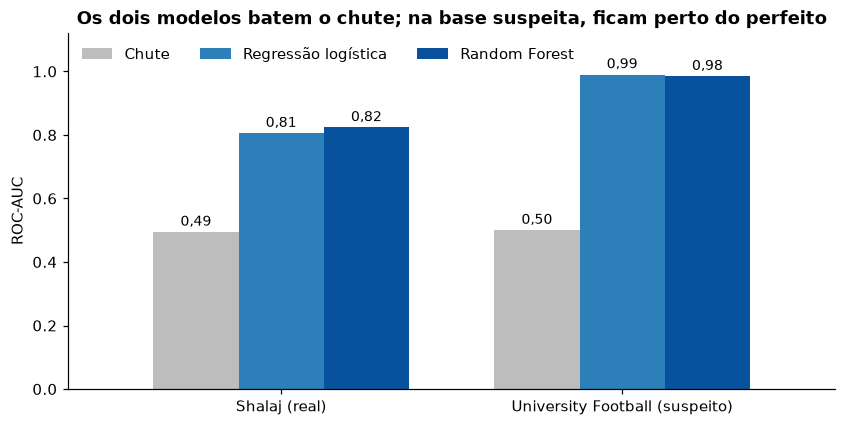

,Chute,Regressão logística,Random Forest
Shalaj (real),0.494,0.805,0.824
University Football (suspeito),0.500,0.990,0.984


In [7]:
modelos = {"prevalencia": "Chute", "logistica": "Regressão logística", "rf_sigmoid": "Random Forest"}
comp = pd.DataFrame({
    "Shalaj (real)": {modelos[k]: v["roc_auc"] for k, v in shalaj["metrics_oof"].items()},
    "University Football (suspeito)": {modelos[k]: v["roc_auc"] for k, v in uf["metrics_label_classification_oof"].items()},
}).T
ax = comp.plot.bar(figsize=(9, 4.2), color=["#bdbdbd", "#2c7fb8", "#08519c"], rot=0, width=0.75)
for c in ax.containers:
    ax.bar_label(c, labels=[br(v) for v in c.datavalues], padding=2, fontsize=9)
ax.set_ylim(0, 1.12)
ax.set_ylabel("ROC-AUC")
ax.set_title("Os dois modelos batem o chute; na base suspeita, ficam perto do perfeito")
ax.legend(frameon=False, ncol=3, loc="upper left")
salvar("05_modelo_contra_chute.png")
comp.round(3)

## 6. SoccerMon: em que o modelo se apoia

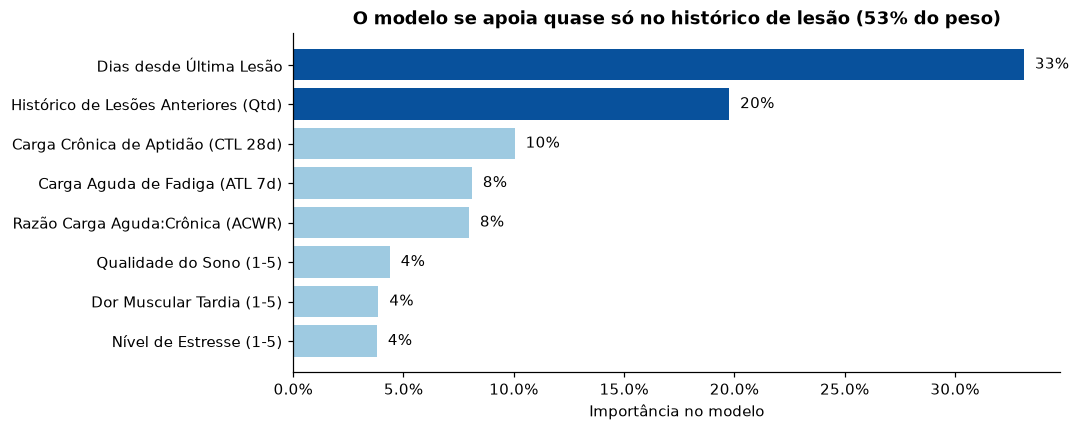

In [8]:
imp = pd.DataFrame(re.findall(r"^\d+\s+(.+?)\s{2,}(\d\.\d{6})\s+(\d\.\d{6})\s*$", saida_da_celula(MON_NB, 21), re.M),
                   columns=["Variável", "Importância", "Desvio"]).astype({"Importância": float, "Desvio": float})
top = imp.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top["Variável"], top["Importância"], color=["#08519c" if i >= 6 else "#9ecae1" for i in range(len(top))])
for i, v in enumerate(top["Importância"]):
    ax.text(v + 0.005, i, f"{v:.0%}", va="center")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Importância no modelo")
ax.set_title(f"O modelo se apoia quase só no histórico de lesão ({imp['Importância'].head(2).sum():.0%} do peso)")
salvar("06_soccermon_importancia.png")

## 7. SoccerNet-GSR: base de vídeo, sem dado de lesão

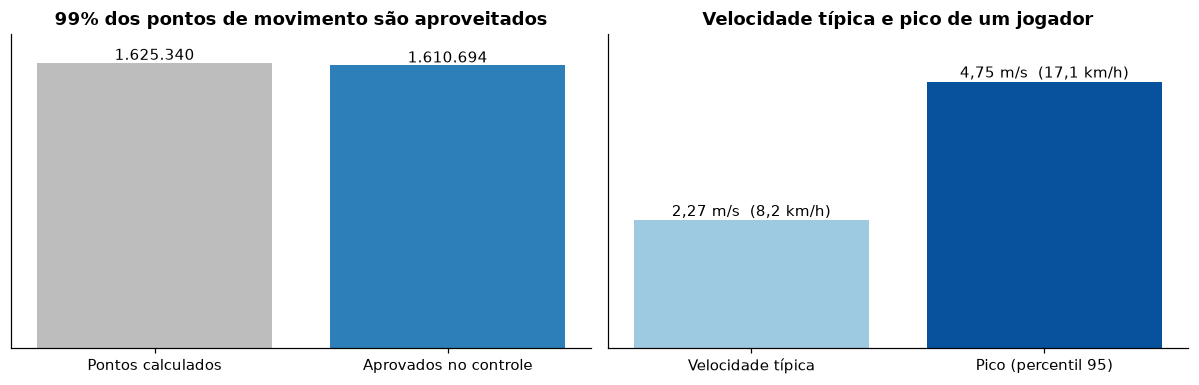

164 trechos. 9 jogos. 3.481 trajetórias.
Tem dado de lesão? não


In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
antes, depois = gsr["motion_points_before_qc"], gsr["motion_points_after_qc"]
a.bar(["Pontos calculados", "Aprovados no controle"], [antes, depois], color=["#bdbdbd", "#2c7fb8"])
for i, v in enumerate([antes, depois]):
    a.text(i, v * 1.01, f"{v:,}".replace(",", "."), ha="center")
a.set_title(f"{depois / antes:.0%} dos pontos de movimento são aproveitados")
a.set_ylim(0, antes * 1.1)
a.set_yticks([])
vel = [gsr["median_track_mean_speed_m_s"], gsr["median_track_p95_speed_m_s"]]
b.bar(["Velocidade típica", "Pico (percentil 95)"], vel, color=["#9ecae1", "#08519c"])
for i, v in enumerate(vel):
    b.text(i, v + 0.08, f"{br(v)} m/s  ({br(v * 3.6, 1)} km/h)", ha="center")
b.set_title("Velocidade típica e pico de um jogador")
b.set_ylim(0, max(vel) * 1.18)
b.set_yticks([])
plt.tight_layout()
salvar("07_soccernet.png")
print(f"{gsr['clips']} trechos, {gsr['games_observed']} jogos, {gsr['local_tracklets']:,} trajetórias.".replace(",", "."))
print("Tem dado de lesão?", "sim" if gsr["injury_target_available"] else "não")

## Conclusão

- **Notas altas não provam muito.** As maiores notas (0,99 e 0,90) vêm de bases inventadas ou suspeitas.
- **Nas bases reais, as notas ficam em torno de 0,82 a 0,84.** O SoccerMon tem tão poucas lesões anotadas que quase todos os alertas seriam falsos.
- **Alguns padrões se repetem em várias bases:** dormir menos, recuperar pior, mais estresse e ter lesão anterior andam junto com lesão.
- **Outros mudam de uma base para outra:** a assimetria muscular é forte no SIRP-600 e quase zero no Shalaj. A idade só pesa no Shalaj.
- **Nenhum modelo está pronto para decidir se um atleta joga.** Eles mostram padrões, não causas.